In [ ]:
# 📸 Pizarra Snap

## Sistema inteligente de captura de pizarras mediante visión por computadora

### Objetivo

Desarrollar un sistema capaz de detectar acciones visuales realizadas por un docente sobre una pizarra para generar capturas automáticas sin utilizar comandos de voz, teclado, mouse ni botones electrónicos.

El sistema reconocerá tres tipos de eventos:

- 📸 Captura normal
- ⭐ Concepto importante
- 📌 Fin de tema

Luego de detectar un evento, analizará una breve secuencia de frames posteriores para seleccionar automáticamente la imagen de mejor calidad.

---

## Etapa 1 — Video y frames

En esta primera etapa voy a:

1. cargar el video de prueba;
2. abrirlo con OpenCV;
3. obtener sus características;
4. comprender cómo un video está formado por una secuencia de frames;
5. extraer y visualizar algunos frames.

In [1]:
# Importo OpenCV para trabajar con videos e imágenes.
import cv2

# Importo NumPy para trabajar con los frames como matrices de píxeles.
import numpy as np

# Importo Matplotlib para visualizar imágenes y resultados.
import matplotlib.pyplot as plt

# Importo herramientas de Colab para poder cargar archivos desde la computadora.
from google.colab import files

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [3]:
# Abro el selector de archivos para cargar el video desde mi computadora.
archivos_subidos = files.upload()

# Obtengo automáticamente el nombre del archivo que acabo de subir.
nombre_video = list(archivos_subidos.keys())[0]

# Muestro el nombre para comprobar que el archivo se cargó correctamente.
print("Video cargado:", nombre_video)

Saving proyecto_pizzarasnap.mp4 to proyecto_pizzarasnap.mp4
Video cargado: proyecto_pizzarasnap.mp4


In [4]:
# Abro el video con OpenCV usando el nombre del archivo que cargué.
video = cv2.VideoCapture(nombre_video)

# Verifico que OpenCV haya podido abrir correctamente el video.
if video.isOpened():
    print("Video abierto correctamente.")
else:
    print("Error: no se pudo abrir el video.")

Video abierto correctamente.


In [5]:
# Obtengo la cantidad de frames que contiene el video.
total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))

# Obtengo la cantidad de frames por segundo.
fps = video.get(cv2.CAP_PROP_FPS)

# Obtengo el ancho del video en píxeles.
ancho = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))

# Obtengo el alto del video en píxeles.
alto = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))

# Calculo la duración aproximada del video en segundos.
duracion = total_frames / fps

# Muestro los datos principales del video.
print("Resolución:", ancho, "x", alto)
print("FPS:", fps)
print("Cantidad de frames:", total_frames)
print("Duración aproximada:", round(duracion, 2), "segundos")

Resolución: 1920 x 1080
FPS: 28.843967150979154
Cantidad de frames: 1522
Duración aproximada: 52.77 segundos


In [6]:
# Coloco el video nuevamente al comienzo para asegurarme de leer el primer frame.
video.set(cv2.CAP_PROP_POS_FRAMES, 0)

# Leo el primer frame del video.
# "leido" indica si OpenCV pudo leerlo correctamente.
# "frame" contiene la imagen obtenida.
leido, frame = video.read()

# Verifico que el primer frame se haya leído correctamente.
if leido:
    print("Primer frame leído correctamente.")
else:
    print("Error: no se pudo leer el primer frame.")

Primer frame leído correctamente.


In [7]:
# Muestro el tipo de dato almacenado en la variable frame.
print("Tipo de frame:", type(frame))

# Muestro la forma o dimensiones de la imagen.
print("Shape del frame:", frame.shape)

# Muestro el tipo de dato utilizado para almacenar cada valor de píxel.
print("Tipo de dato de los píxeles:", frame.dtype)

Tipo de frame: <class 'numpy.ndarray'>
Shape del frame: (1080, 1920, 3)
Tipo de dato de los píxeles: uint8


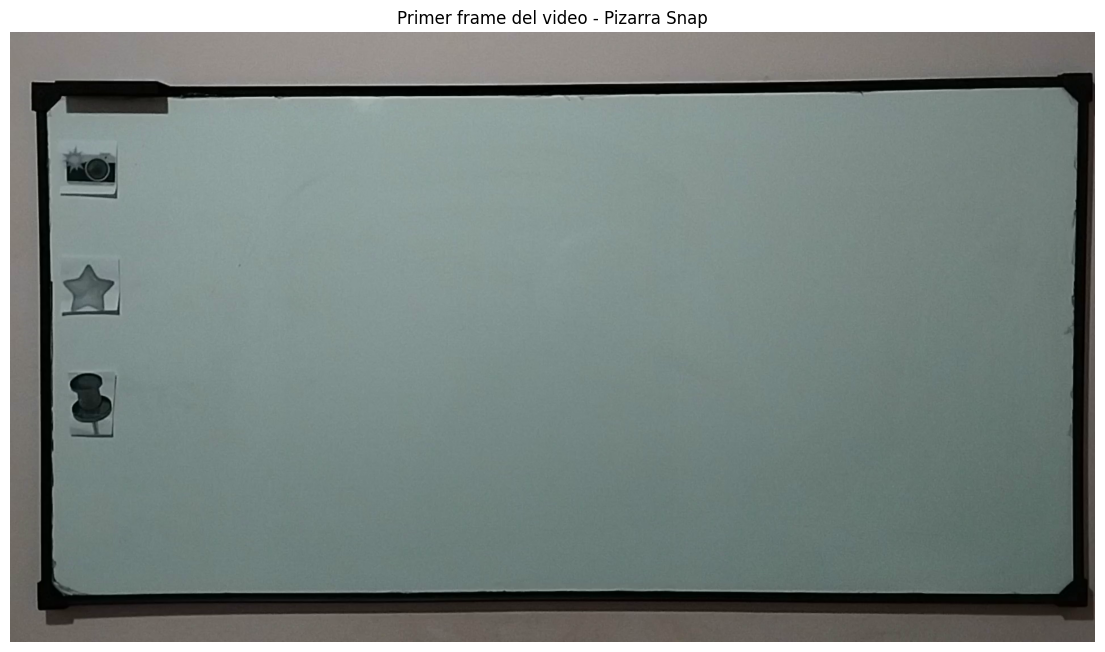

In [8]:
# Convierto el frame de BGR a RGB para mostrar correctamente los colores con Matplotlib.
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

# Creo una figura para visualizar la imagen.
plt.figure(figsize=(14, 8))

# Muestro el primer frame.
plt.imshow(frame_rgb)

# Agrego un título descriptivo.
plt.title("Primer frame del video - Pizarra Snap")

# Oculto los números de los ejes porque ahora me interesa observar la imagen.
plt.axis("off")

# Muestro el resultado.
plt.show()

In [9]:
# Elijo un píxel aproximadamente en el centro de la imagen.
fila = 540
columna = 960

# Obtengo los valores de color de ese píxel.
pixel = frame[fila, columna]

# Muestro el resultado.
print("Píxel seleccionado:", pixel)
print("Canal Azul (B):", pixel[0])
print("Canal Verde (G):", pixel[1])
print("Canal Rojo (R):", pixel[2])

Píxel seleccionado: [142 144 126]
Canal Azul (B): 142
Canal Verde (G): 144
Canal Rojo (R): 126


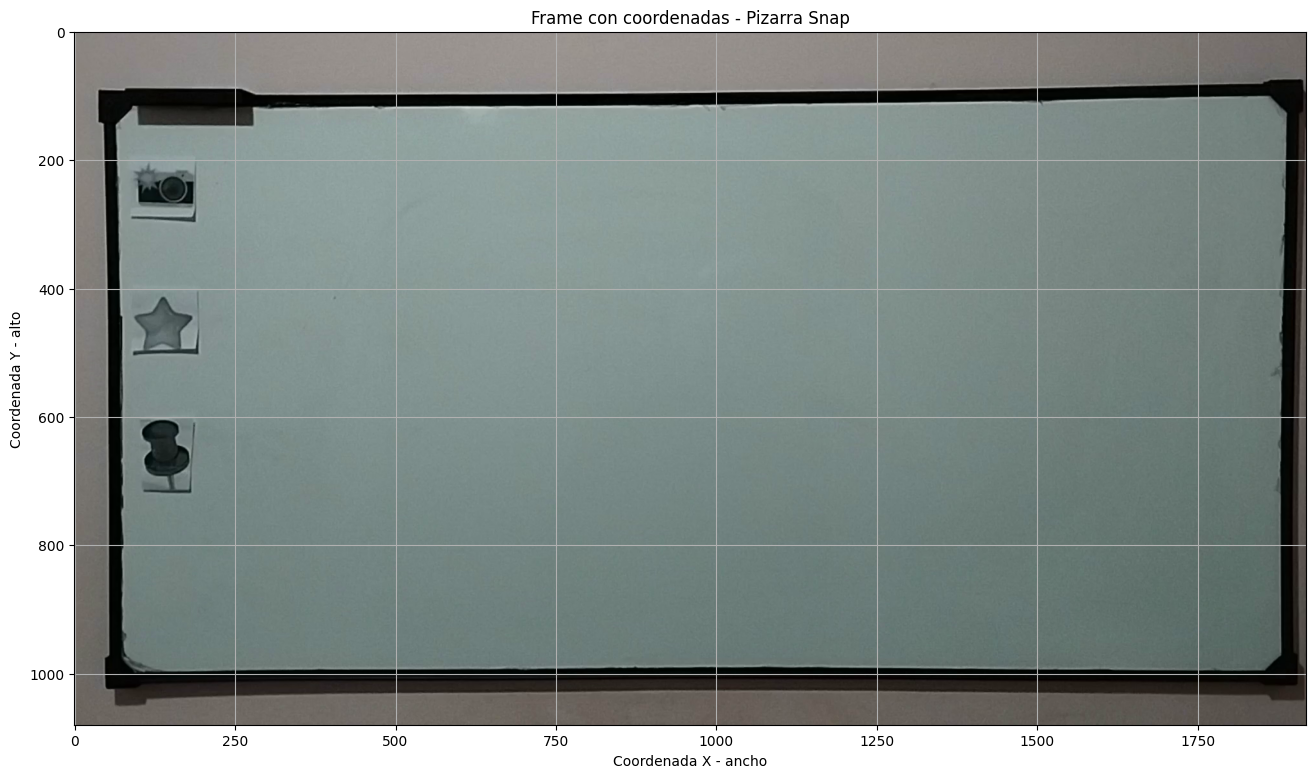

In [10]:
# Convierto el frame de BGR a RGB para visualizar correctamente los colores.
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

# Creo una figura grande para observar bien las coordenadas.
plt.figure(figsize=(16, 9))

# Muestro el frame completo.
plt.imshow(frame_rgb)

# Agrego un título.
plt.title("Frame con coordenadas - Pizarra Snap")

# Mantengo visibles los ejes para identificar posiciones dentro de la imagen.
plt.xlabel("Coordenada X - ancho")
plt.ylabel("Coordenada Y - alto")

# Muestro una grilla para facilitar la ubicación de las zonas.
plt.grid()

plt.show()

In [13]:
# Defino las coordenadas corregidas de las tres regiones de interés (ROI).
# Ajusto cada región para que encierre solamente su símbolo correspondiente.

# ROI 1 - Captura normal
x1_normal, x2_normal = 75, 210
y1_normal, y2_normal = 190, 300

# ROI 2 - Concepto importante
x1_importante, x2_importante = 75, 210
y1_importante, y2_importante = 400, 510

# ROI 3 - Fin de tema
x1_fin, x2_fin = 75, 215
y1_fin, y2_fin = 585, 740

print("Coordenadas corregidas de las ROI definidas correctamente.")

Coordenadas corregidas de las ROI definidas correctamente.


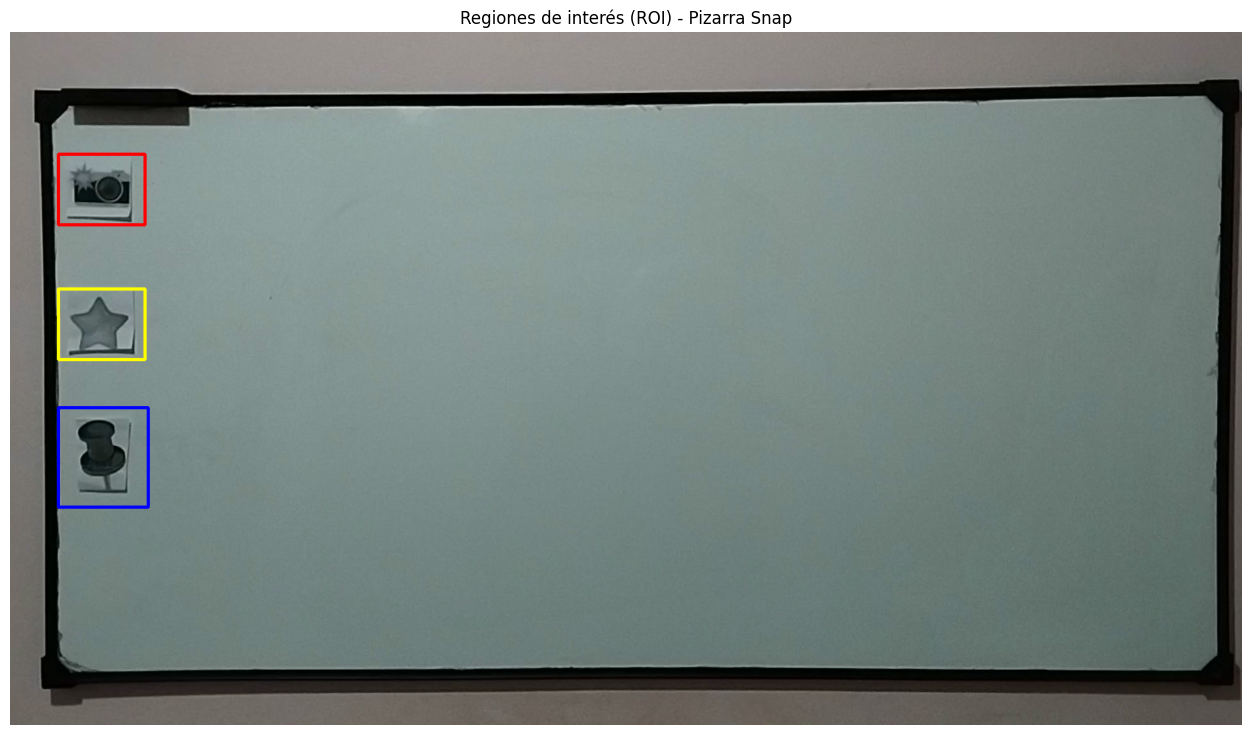

In [14]:
# Creo una copia del frame para dibujar las ROI sin modificar la imagen original.
frame_roi = frame.copy()

# Dibujo la ROI de Captura normal.
cv2.rectangle(
    frame_roi,
    (x1_normal, y1_normal),
    (x2_normal, y2_normal),
    (0, 0, 255),
    3
)

# Dibujo la ROI de Concepto importante.
cv2.rectangle(
    frame_roi,
    (x1_importante, y1_importante),
    (x2_importante, y2_importante),
    (0, 255, 255),
    3
)

# Dibujo la ROI de Fin de tema.
cv2.rectangle(
    frame_roi,
    (x1_fin, y1_fin),
    (x2_fin, y2_fin),
    (255, 0, 0),
    3
)

# Convierto de BGR a RGB para visualizar correctamente con Matplotlib.
frame_roi_rgb = cv2.cvtColor(frame_roi, cv2.COLOR_BGR2RGB)

# Muestro el frame completo con las tres regiones marcadas.
plt.figure(figsize=(16, 9))
plt.imshow(frame_roi_rgb)
plt.title("Regiones de interés (ROI) - Pizarra Snap")
plt.axis("off")
plt.show()

In [15]:
# Recorto las tres regiones de interés directamente desde la matriz del frame.
# Uso slicing de NumPy con la forma: frame[y1:y2, x1:x2].

# ROI 1 - Captura normal
roi_normal = frame[y1_normal:y2_normal, x1_normal:x2_normal]

# ROI 2 - Concepto importante
roi_importante = frame[
    y1_importante:y2_importante,
    x1_importante:x2_importante
]

# ROI 3 - Fin de tema
roi_fin = frame[y1_fin:y2_fin, x1_fin:x2_fin]

# Muestro las dimensiones de cada ROI.
print("Shape ROI Normal:", roi_normal.shape)
print("Shape ROI Importante:", roi_importante.shape)
print("Shape ROI Fin de tema:", roi_fin.shape)

Shape ROI Normal: (110, 135, 3)
Shape ROI Importante: (110, 135, 3)
Shape ROI Fin de tema: (155, 140, 3)


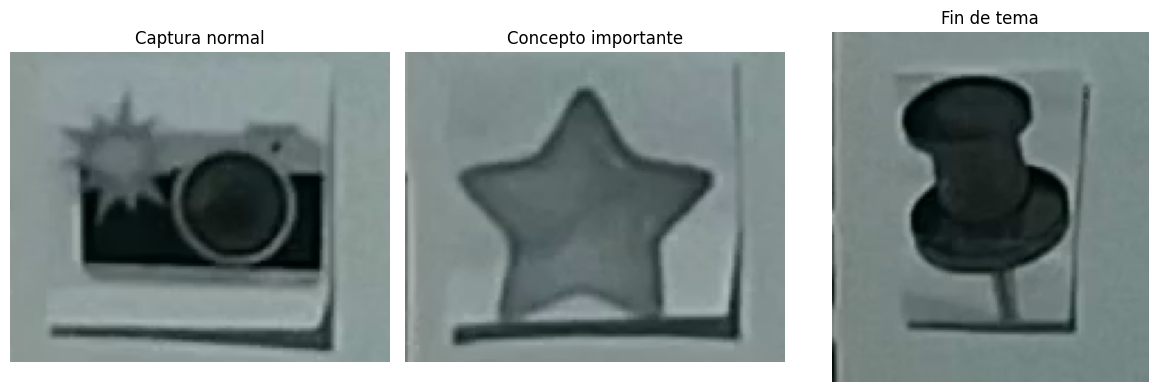

In [16]:
# Convierto cada ROI de BGR a RGB para visualizar correctamente con Matplotlib.
roi_normal_rgb = cv2.cvtColor(roi_normal, cv2.COLOR_BGR2RGB)
roi_importante_rgb = cv2.cvtColor(roi_importante, cv2.COLOR_BGR2RGB)
roi_fin_rgb = cv2.cvtColor(roi_fin, cv2.COLOR_BGR2RGB)

# Creo una figura para visualizar las tres regiones juntas.
plt.figure(figsize=(12, 4))

# Muestro la ROI de Captura normal.
plt.subplot(1, 3, 1)
plt.imshow(roi_normal_rgb)
plt.title("Captura normal")
plt.axis("off")

# Muestro la ROI de Concepto importante.
plt.subplot(1, 3, 2)
plt.imshow(roi_importante_rgb)
plt.title("Concepto importante")
plt.axis("off")

# Muestro la ROI de Fin de tema.
plt.subplot(1, 3, 3)
plt.imshow(roi_fin_rgb)
plt.title("Fin de tema")
plt.axis("off")

# Ajusto automáticamente los espacios entre las imágenes.
plt.tight_layout()

# Muestro el resultado.
plt.show()